# 04 购买预测模型：明天谁会下单？

**业务问题：** 根据用户过去 7 天的行为，预测他第二天会不会购买。预测结果可以用来做精准营销，比如只给高意向用户推送优惠券，节省营销预算。

**建模设计：**

| 数据集 | 特征窗口（过去 7 天） | 预测日（标签） |
|---|---|---|
| 训练集 | 11 月 25 日至 12 月 1 日 | 12 月 2 日是否购买 |
| 测试集 | 11 月 26 日至 12 月 2 日 | 12 月 3 日是否购买 |

- **按时间切分**而不是随机切分：模拟"用历史预测未来"的真实场景，避免用未来信息预测过去（数据泄漏）。
- **类别不平衡**：第二天购买的用户只占少数，模型训练时调整类别权重，评估时重点看精确率—召回率曲线，而不只是准确率。
- **模型对比**：业务规则基准 → 逻辑回归（可解释）→ 随机森林 → XGBoost。

In [1]:
# 在 Google Colab 上运行时先执行这一格；在自己电脑上运行会自动跳过
import os, sys, subprocess
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/ecommerce-user-behavior/notebooks")
    subprocess.run("pip -q install duckdb xgboost", shell=True, check=True)
    subprocess.run("apt-get -qq install -y fonts-noto-cjk > /dev/null", shell=True, check=True)
    import matplotlib.font_manager as fm
    for f in fm.findSystemFonts():
        if "NotoSansCJK" in f:
            fm.fontManager.addfont(f)
    print("Colab 环境准备完成，当前目录：", os.getcwd())

Mounted at /content/drive
Colab 环境准备完成，当前目录： /content/drive/MyDrive/ecommerce-user-behavior/notebooks


In [2]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, precision_score, recall_score)
from xgboost import XGBClassifier
import config, utils

utils.setup_plot()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
con = utils.connect()
BLUE, ORANGE, GREEN, GREY = "#3B6FB6", "#E07B39", "#4C9A6A", "#9AA5B1"
MAX_TRAIN_ROWS = 600_000   # 训练样本上限，电脑慢可以调小

## 1. 用 SQL 构造特征和标签

| 特征类别 | 具体特征 |
|---|---|
| 行为次数 | 过去 7 天、3 天、1 天的浏览、收藏、加购、购买次数 |
| 活跃度 | 活跃天数、浏览商品数、浏览类目数 |
| 时间间隔 | 距最近一次行为、最近一次加购、最近一次购买的小时数 |
| 比率 | 加购转购买比、浏览转加购比 |

In [3]:
def build_features(feat_start, label_date):
    # 用 [feat_start, label_date) 的行为构造特征，标签为 label_date 当天是否购买
    recent = lambda days, beh: (
        f"COUNT(*) FILTER (WHERE behavior_type = '{beh}' "
        f"AND event_date >= DATE '{label_date}' - INTERVAL {days} DAY) AS {beh}_{days}d"
    )
    recent_cols = ",\n            ".join(recent(d, b) for d in (3, 1) for b in ("pv", "fav", "cart", "buy"))
    sql = f'''
        WITH w AS (
            SELECT * FROM ub
            WHERE event_date >= DATE '{feat_start}' AND event_date < DATE '{label_date}'
        ),
        feats AS (
            SELECT
                user_id,
                COUNT(*) FILTER (WHERE behavior_type = 'pv')   AS pv_7d,
                COUNT(*) FILTER (WHERE behavior_type = 'fav')  AS fav_7d,
                COUNT(*) FILTER (WHERE behavior_type = 'cart') AS cart_7d,
                COUNT(*) FILTER (WHERE behavior_type = 'buy')  AS buy_7d,
                {recent_cols},
                COUNT(DISTINCT event_date)                     AS active_days,
                COUNT(DISTINCT item_id)                        AS n_items,
                COUNT(DISTINCT category_id)                    AS n_categories,
                date_diff('hour', MAX(event_time), TIMESTAMP '{label_date}') AS hours_since_action,
                date_diff('hour', MAX(event_time) FILTER (WHERE behavior_type = 'cart'),
                          TIMESTAMP '{label_date}')            AS hours_since_cart,
                date_diff('hour', MAX(event_time) FILTER (WHERE behavior_type = 'buy'),
                          TIMESTAMP '{label_date}')            AS hours_since_buy
            FROM w
            GROUP BY user_id
        ),
        labels AS (
            SELECT DISTINCT user_id, 1 AS label
            FROM ub
            WHERE event_date = DATE '{label_date}' AND behavior_type = 'buy'
        )
        SELECT f.*, COALESCE(l.label, 0) AS label
        FROM feats f
        LEFT JOIN labels l USING (user_id)
    '''
    df = con.execute(sql).df()
    never = 8 * 24   # 窗口内从未加购或购买，填一个比窗口更长的时间
    df[["hours_since_cart", "hours_since_buy"]] = df[["hours_since_cart", "hours_since_buy"]].fillna(never)
    df["cart_to_buy"] = df["buy_7d"] / (df["cart_7d"] + 1)
    df["pv_to_cart"] = df["cart_7d"] / (df["pv_7d"] + 1)
    return df


train = build_features("2017-11-25", "2017-12-02")
test = build_features("2017-11-26", "2017-12-03")
feature_cols = [c for c in train.columns if c not in ("user_id", "label")]

for name, df in [("训练集", train), ("测试集", test)]:
    print(f"{name}：{len(df):,} 个用户，次日购买占比 {df['label'].mean():.2%}")
print(f"特征数：{len(feature_cols)}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

训练集：99,056 个用户，次日购买占比 17.71%
测试集：99,052 个用户，次日购买占比 17.40%
特征数：20


In [4]:
if len(train) > MAX_TRAIN_ROWS:
    train = train.sample(MAX_TRAIN_ROWS, random_state=config.RANDOM_STATE)

X_train, y_train = train[feature_cols].astype(float), train["label"]
X_test, y_test = test[feature_cols].astype(float), test["label"]
base_rate = y_test.mean()
pos_weight = (y_train == 0).sum() / max((y_train == 1).sum(), 1)

## 2. 训练模型

- **业务规则基准**：最近一天有加购就预测会买。模型至少要比这条简单规则好，才有上线价值。
- **逻辑回归**：特征先做 `log(1 + x)` 和标准化，系数可以直接解释。
- **随机森林、XGBoost**：能捕捉非线性关系和特征交互。XGBoost 留出 10% 训练数据做早停，防止过拟合。

In [5]:
models = {}

models["逻辑回归"] = make_pipeline(
    FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=2000),
).fit(X_train, y_train)

models["随机森林"] = RandomForestClassifier(
    n_estimators=200, max_depth=12, min_samples_leaf=50,
    class_weight="balanced_subsample", n_jobs=-1, random_state=config.RANDOM_STATE,
).fit(X_train, y_train)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.1, stratify=y_train, random_state=config.RANDOM_STATE)
models["XGBoost"] = XGBClassifier(
    n_estimators=1000, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=pos_weight, eval_metric="aucpr", early_stopping_rounds=50,
    tree_method="hist", n_jobs=-1, random_state=config.RANDOM_STATE,
).fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
print(f"XGBoost 早停于第 {models['XGBoost'].best_iteration} 轮")

XGBoost 早停于第 40 轮


## 3. 在测试集上评估

| 指标 | 含义 |
|---|---|
| ROC 曲线下面积 | 随机抽一个购买用户和一个未购买用户，模型给前者打分更高的概率 |
| 平均精确率 | 精确率—召回率曲线下的面积，类别不平衡时比 ROC 更能反映效果 |
| 前 10% 命中率 | 按得分取前 10% 的用户，其中真正购买的比例 |
| 前 10% 覆盖率 | 前 10% 用户覆盖了多少实际购买用户 |
| 提升度 | 前 10% 命中率 ÷ 整体购买率，即比随机投放好多少倍 |

In [6]:
def top_k_metrics(y_true, score, frac=0.10):
    k = max(1, int(len(score) * frac))
    top = np.argsort(-score)[:k]
    hit = y_true.values[top].mean()
    coverage = y_true.values[top].sum() / y_true.sum()
    return hit, coverage, hit / y_true.mean()


rows, scores = [], {}
rule_pred = (X_test["cart_1d"] > 0).astype(int)
rows.append({"模型": "规则：最近一天有加购", "ROC曲线下面积": np.nan, "平均精确率": np.nan,
             "前10%命中率": np.nan, "前10%覆盖率": np.nan, "提升度": np.nan,
             "规则精确率": precision_score(y_test, rule_pred), "规则召回率": recall_score(y_test, rule_pred)})
for name, m in models.items():
    s = m.predict_proba(X_test)[:, 1]
    scores[name] = s
    hit, cov, lift = top_k_metrics(y_test, s)
    rows.append({"模型": name, "ROC曲线下面积": roc_auc_score(y_test, s),
                 "平均精确率": average_precision_score(y_test, s),
                 "前10%命中率": hit, "前10%覆盖率": cov, "提升度": lift})
result = pd.DataFrame(rows).set_index("模型")
print(f"测试集整体购买率：{base_rate:.2%}")
result

测试集整体购买率：17.40%


,ROC曲线下面积,平均精确率,前10%命中率,前10%覆盖率,提升度,规则精确率,规则召回率
模型,,,,,,,
规则：最近一天有加购,NaN,NaN,NaN,NaN,NaN,0.2088,0.4015
逻辑回归,0.6187,0.2605,0.3155,0.1813,1.8128,NaN,NaN
随机森林,0.6163,0.2621,0.3136,0.1802,1.8018,NaN,NaN
XGBoost,0.6158,0.2623,0.3143,0.1806,1.8058,NaN,NaN


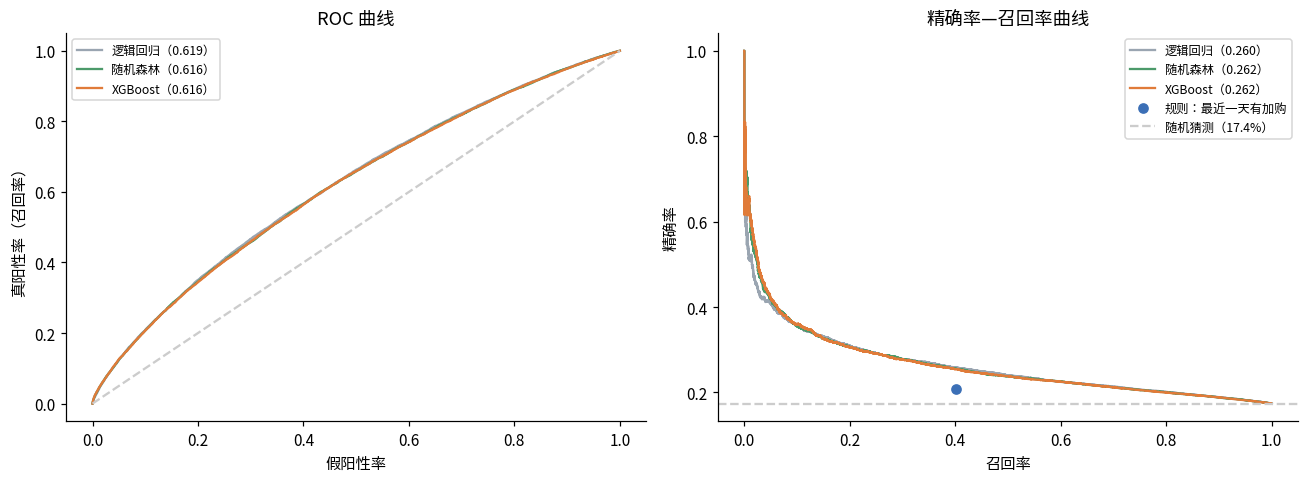

In [7]:
colors = {"逻辑回归": GREY, "随机森林": GREEN, "XGBoost": ORANGE}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=colors[name], label=f"{name}（{roc_auc_score(y_test, s):.3f}）")
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[1].plot(rec, prec, color=colors[name], label=f"{name}（{average_precision_score(y_test, s):.3f}）")
axes[0].plot([0, 1], [0, 1], "--", color="#cccccc")
axes[0].set(xlabel="假阳性率", ylabel="真阳性率（召回率）", title="ROC 曲线")
axes[1].scatter(recall_score(y_test, rule_pred), precision_score(y_test, rule_pred),
                color=BLUE, zorder=5, label="规则：最近一天有加购")
axes[1].axhline(base_rate, ls="--", color="#cccccc", label=f"随机猜测（{base_rate:.1%}）")
axes[1].set(xlabel="召回率", ylabel="精确率", title="精确率—召回率曲线")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
_ = utils.save_fig(fig, "04_模型评估曲线")

效果最好的模型：XGBoost；触达得分前 10% / 20% / 30% 的用户，分别覆盖 18.1% / 31.5% / 42.8% 的次日购买用户


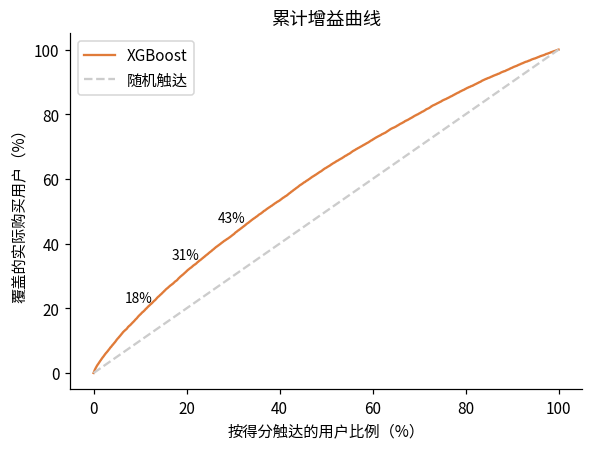

In [8]:
# 累计增益曲线：按 XGBoost 得分从高到低触达用户，能覆盖多少实际购买者
best = result["平均精确率"].idxmax()
s = scores[best]
order = np.argsort(-s)
cum_gain = np.cumsum(y_test.values[order]) / y_test.sum()
x = np.arange(1, len(s) + 1) / len(s)

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(x * 100, cum_gain * 100, color=ORANGE, label=best)
ax.plot([0, 100], [0, 100], "--", color="#cccccc", label="随机触达")
for frac in (0.1, 0.2, 0.3):
    i = int(len(s) * frac) - 1
    ax.annotate(f"{cum_gain[i]:.0%}", (frac * 100, cum_gain[i] * 100),
                textcoords="offset points", xytext=(-10, 8), fontsize=9)
ax.set(xlabel="按得分触达的用户比例（%）", ylabel="覆盖的实际购买用户（%）", title="累计增益曲线")
ax.legend()
_ = utils.save_fig(fig, "04_累计增益曲线")
print(f"效果最好的模型：{best}；触达得分前 10% / 20% / 30% 的用户，"
      f"分别覆盖 {cum_gain[int(len(s)*0.1)-1]:.1%} / {cum_gain[int(len(s)*0.2)-1]:.1%} / "
      f"{cum_gain[int(len(s)*0.3)-1]:.1%} 的次日购买用户")

## 4. 哪些行为最能预测购买？

XGBoost 最重要的 5 个特征： ['buy_7d', 'hours_since_buy', 'hours_since_cart', 'cart_to_buy', 'buy_3d']
逻辑回归正向作用最强的 3 个特征： ['buy_7d', 'cart_to_buy', 'n_items']


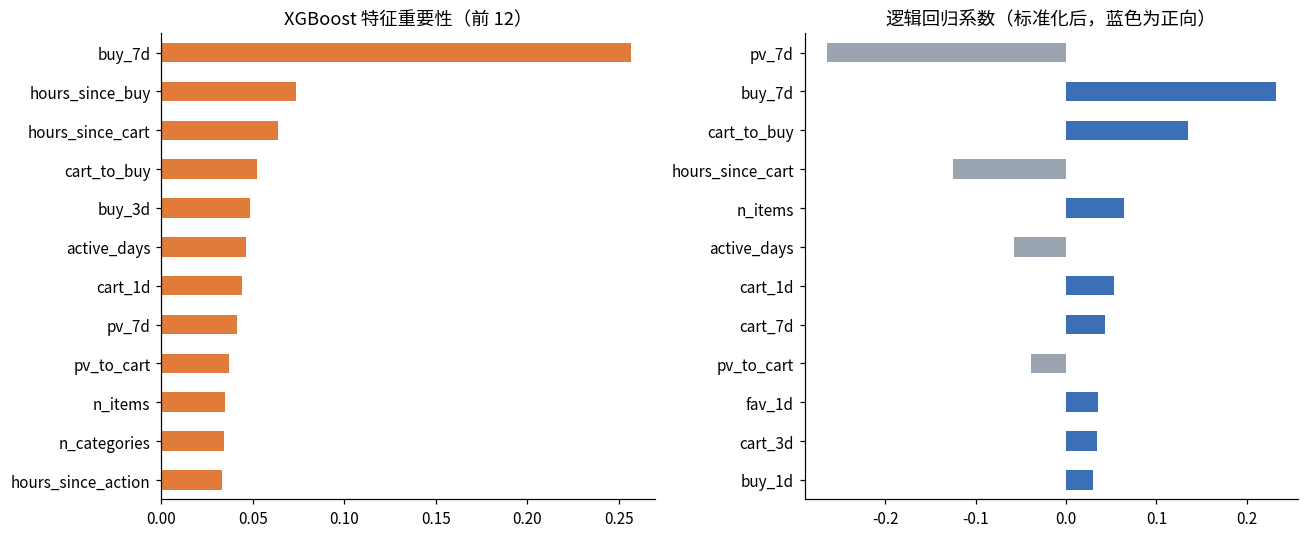

In [9]:
imp = pd.Series(models["XGBoost"].feature_importances_, index=feature_cols).sort_values()
coef = pd.Series(models["逻辑回归"][-1].coef_[0], index=feature_cols).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
imp.tail(12).plot.barh(ax=axes[0], color=ORANGE)
axes[0].set_title("XGBoost 特征重要性（前 12）")
top_coef = coef.reindex(coef.abs().sort_values().tail(12).index)
top_coef.plot.barh(ax=axes[1], color=[BLUE if v > 0 else GREY for v in top_coef])
axes[1].set_title("逻辑回归系数（标准化后，蓝色为正向）")
fig.tight_layout()
_ = utils.save_fig(fig, "04_特征重要性")

print("XGBoost 最重要的 5 个特征：", list(imp.tail(5).index[::-1]))
print("逻辑回归正向作用最强的 3 个特征：", list(coef.tail(3).index[::-1]))

In [10]:
result.to_csv(config.RESULTS_DIR / "04_模型对比.csv", encoding="utf-8-sig")
r_best = result.loc[best]
utils.update_summary("04_购买预测", {
    "训练集用户数": int(len(train)),
    "测试集用户数": int(len(test)),
    "测试集购买率": round(float(base_rate), 4),
    "最佳模型": best,
    "各模型ROC曲线下面积": {k: round(float(v), 4) for k, v in result["ROC曲线下面积"].dropna().items()},
    "各模型平均精确率": {k: round(float(v), 4) for k, v in result["平均精确率"].dropna().items()},
    "最佳模型_前10%命中率": round(float(r_best["前10%命中率"]), 4),
    "最佳模型_前10%覆盖率": round(float(r_best["前10%覆盖率"]), 4),
    "最佳模型_提升度": round(float(r_best["提升度"]), 2),
    "规则基准_精确率": round(float(result.loc["规则：最近一天有加购", "规则精确率"]), 4),
    "规则基准_召回率": round(float(result.loc["规则：最近一天有加购", "规则召回率"]), 4),
    "XGBoost前5特征": list(imp.tail(5).index[::-1]),
})
print("已写入 results/summary.json")

已写入 results/summary.json


## 小结（跑完真实数据后填写）

- 最佳模型和效果：
- 和规则基准相比提升了多少：
- 最能预测购买的行为：
- 业务应用：按模型得分触达前 10% 用户，能覆盖多少购买用户，比随机投放好几倍
- 局限：只用了 9 天数据，没有商品价格、用户画像等信息；没有活跃的用户不在预测范围内